In [1]:
import copy
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms, models
from torchvision.models import ResNet18_Weights

### Settings

In [2]:
SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_EPOCHS = 12
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 3

# Dataset folder beside your notebook.
# If stored elsewhere, replace this with its full path.
DATA_DIR = Path("generated_circuits2")

# Save training results separately from the dataset.
RESULTS_DIR = Path("circuit_resnet_results")
CHECKPOINT_PATH = RESULTS_DIR / "best_circuit_resnet18.pth"

EXPECTED_CLASSES = sorted([
    "voltage_divider",
    "current_divider",
    "low_pass_filter",
    "high_pass_filter",
    "band_pass_filter",
])

NUM_CLASSES = 5

# Target approximately 70% training, 15% validation, 15% testing.
# Actual percentages may differ to keep circuit templates together.
VAL_FRACTION = 0.15
TEST_FRACTION = 0.15

# Start with pretrained ResNet18 weights.
USE_PRETRAINED = True

### Set Seed For Reproducibility

In [3]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

### Set Up Stuff for Torch311

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU


### Set up Datasets

In [5]:
DATA_DIR = DATA_DIR.expanduser().resolve()

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_DIR}\n"
        f"Jupyter working directory: {Path.cwd()}\n"
        "Set DATA_DIR in Settings to the full path of generated_circuits2."
    )

missing_classes = [
    name for name in EXPECTED_CLASSES
    if not (DATA_DIR / name).is_dir()
]

if missing_classes:
    raise ValueError(f"Missing class folders: {missing_classes}")

class_names = EXPECTED_CLASSES.copy()

class_to_idx = {
    name: index for index, name in enumerate(class_names)
}

idx_to_class = {
    index: name for name, index in class_to_idx.items()
}

assert len(class_names) == NUM_CLASSES == 5

print("Dataset:", DATA_DIR)
print("Number of classes:", NUM_CLASSES)
print("Class mapping:", class_to_idx)

Dataset: C:\Users\spiro\OneDrive\Documents\GitHub\intro_ai_project\generated_circuits2
Number of classes: 5
Class mapping: {'band_pass_filter': 0, 'current_divider': 1, 'high_pass_filter': 2, 'low_pass_filter': 3, 'voltage_divider': 4}


In [6]:
csv_path = DATA_DIR / "labels.csv"

if not csv_path.is_file():
    raise FileNotFoundError(
        f"Missing {csv_path}. Keep labels.csv inside generated_circuits2."
    )

metadata = pd.read_csv(csv_path, encoding="utf-8-sig")

required = {"filename", "circuit_type", "template_id"}
missing_columns = required - set(metadata.columns)

if missing_columns:
    raise ValueError(
        f"labels.csv is missing columns: {sorted(missing_columns)}"
    )

if metadata.empty or metadata[list(required)].isna().any().any():
    raise ValueError("labels.csv is empty or contains missing required values.")

if set(metadata["circuit_type"]) != set(class_names):
    raise ValueError("The CSV must contain exactly the five circuit classes.")

paths = []

for row in metadata.itertuples(index=False):
    relative = Path(str(row.filename).replace("\\", "/"))
    path = (DATA_DIR / relative).resolve()

    if relative.is_absolute() or DATA_DIR not in path.parents:
        raise ValueError(f"Invalid relative image path: {row.filename}")

    if not relative.parts or relative.parts[0] != row.circuit_type:
        raise ValueError(f"Folder and CSV class disagree: {row.filename}")

    if not path.is_file():
        raise FileNotFoundError(f"Image listed in CSV is missing: {path}")

    paths.append(str(path))

all_df = metadata.rename(columns={"circuit_type": "class"}).copy()
all_df["path"] = paths

if all_df["path"].duplicated().any():
    raise ValueError("The CSV contains duplicate image paths.")

if "sha256" in all_df.columns:
    if all_df["sha256"].dropna().duplicated().any():
        raise ValueError("The CSV contains duplicate image hashes.")

if all_df.groupby("template_id")["class"].nunique().max() != 1:
    raise ValueError("A template ID is assigned to multiple classes.")

print("Images per class:")
print(all_df["class"].value_counts().reindex(class_names).to_string())
print(f"\nTotal images: {len(all_df):,}")

Images per class:
class
band_pass_filter    500
current_divider     500
high_pass_filter    500
low_pass_filter     500
voltage_divider     500

Total images: 2,500


### Set up Train/Val Split

In [7]:
if not (
    0 < VAL_FRACTION < 1
    and 0 < TEST_FRACTION < 1
    and VAL_FRACTION + TEST_FRACTION < 1
):
    raise ValueError("Validation/test fractions must sum to less than 1.")

rng = np.random.default_rng(SEED)
parts = {"train": [], "val": [], "test": []}

for name in class_names:
    subset = all_df[all_df["class"] == name]

    groups = np.array(
        sorted(subset["template_id"].unique()),
        dtype=object,
    )

    if len(groups) < 3:
        raise ValueError(
            f"{name} needs at least three different templates."
        )

    rng.shuffle(groups)

    n_val = max(1, round(len(groups) * VAL_FRACTION))
    n_test = max(1, round(len(groups) * TEST_FRACTION))

    if n_val + n_test >= len(groups):
        raise ValueError(f"Too few templates for these fractions: {name}")

    selected = {
        "val": groups[:n_val],
        "test": groups[n_val:n_val + n_test],
        "train": groups[n_val + n_test:],
    }

    for split, group_ids in selected.items():
        part = subset[
            subset["template_id"].isin(group_ids)
        ].copy()

        part["split"] = split
        parts[split].append(part)

splits = {
    split: pd.concat(frames, ignore_index=True)
    for split, frames in parts.items()
}

train_df = splits["train"]
val_df = splits["val"]
test_df = splits["test"]

# Verify that every image appears once and templates never cross splits.
combined = pd.concat(splits.values(), ignore_index=True)

assert len(combined) == len(all_df)
assert combined["path"].is_unique
assert combined.groupby("template_id")["split"].nunique().eq(1).all()

for frame in splits.values():
    assert set(frame["class"]) == set(class_names)

print(
    pd.crosstab(combined["class"], combined["split"]).reindex(
        index=class_names,
        columns=["train", "val", "test"],
    )
)

for split, frame in splits.items():
    print(
        f"{split}: {len(frame):,} images "
        f"({len(frame) / len(all_df):.1%})"
    )

# Save split assignments and class labels for reference.
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

combined.drop(columns="path").to_csv(
    RESULTS_DIR / "dataset_splits.csv",
    index=False,
)

(RESULTS_DIR / "class_to_idx.json").write_text(
    json.dumps(class_to_idx, indent=2),
    encoding="utf-8",
)

split             train  val  test
class                             
band_pass_filter    334   82    84
current_divider     334   82    84
high_pass_filter    333   84    83
low_pass_filter     333   84    83
voltage_divider     334   83    83
train: 1,668 images (66.7%)
val: 415 images (16.6%)
test: 417 images (16.7%)


124

### Transforms For Data

In [8]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    # Small variations in rotation, position, and scale.
    transforms.RandomAffine(
        degrees=5,
        translate=(0.02, 0.02),
        scale=(0.95, 1.0),
        fill=255,
    ),

    transforms.ToTensor(),

    # Normalization used by the pretrained ResNet18.
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

val_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

In [9]:
class FolderDataset(Dataset):
    def __init__(self, dataframe, class_to_idx, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, "path"]
        class_name = self.df.loc[idx, "class"]

        with Image.open(img_path) as source:
            image = source.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        target = self.class_to_idx[class_name]
        return image, target


train_dataset = FolderDataset(
    train_df,
    class_to_idx,
    transform=train_transform,
)

val_dataset = FolderDataset(
    val_df,
    class_to_idx,
    transform=val_test_transform,
)

test_dataset = FolderDataset(
    test_df,
    class_to_idx,
    transform=val_test_transform,
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

Training images: 1668
Validation images: 415
Test images: 417


In [10]:
pin_memory = device.type == "cuda"

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=pin_memory,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=pin_memory,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=pin_memory,
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 53
Validation batches: 13
Test batches: 14


### Model

In [11]:
weights = ResNet18_Weights.DEFAULT if USE_PRETRAINED else None
model = models.resnet18(weights=weights)

# Replace the original output layer with five outputs.
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, NUM_CLASSES)

assert model.fc.out_features == len(class_names) == 5

model = model.to(device)

print("Output layer:", model.fc)
print("Device:", device)
print("Classes:", class_names)

Output layer: Linear(in_features=512, out_features=5, bias=True)
Device: cuda
Classes: ['band_pass_filter', 'current_divider', 'high_pass_filter', 'low_pass_filter', 'voltage_divider']


In [12]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

### Training

In [13]:
train_losses = []
val_losses = []
val_accuracies = []

best_val_acc = -1.0
best_model_wts = copy.deepcopy(model.state_dict())
epochs_no_improve = 0

for epoch in range(NUM_EPOCHS):
    # Training
    model.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for batch_idx, (images, labels) in enumerate(train_loader):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        preds = outputs.argmax(dim=1)
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)

        if batch_idx % 20 == 0:
            print(
                f"Epoch {epoch + 1}/{NUM_EPOCHS}, "
                f"Batch {batch_idx + 1}/{len(train_loader)}, "
                f"Loss: {loss.item():.4f}"
            )

    epoch_train_loss = running_loss / train_total
    epoch_train_acc = train_correct / train_total
    train_losses.append(epoch_train_loss)

    # Validation
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            preds = outputs.argmax(dim=1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    epoch_val_loss = val_running_loss / val_total
    epoch_val_acc = val_correct / val_total

    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    scheduler.step(epoch_val_acc)

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] | "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Acc: {epoch_train_acc:.2%} | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Acc: {epoch_val_acc:.2%}"
    )

    # Keep the weights with the highest validation accuracy.
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        best_model_wts = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1

    if epochs_no_improve >= EARLY_STOPPING_PATIENCE:
        print(f"Early stopping after epoch {epoch + 1}.")
        break

# Restore the best validation model.
model.load_state_dict(best_model_wts)

print(f"\nBest validation accuracy: {best_val_acc:.2%}")

# Save this circuit model and its class mapping.
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "class_names": class_names,
        "class_to_idx": class_to_idx,
        "num_classes": NUM_CLASSES,
        "img_size": IMG_SIZE,
        "seed": SEED,
        "best_val_acc": float(best_val_acc),
    },
    CHECKPOINT_PATH,
)

print("Saved circuit model:", CHECKPOINT_PATH.resolve())

Epoch 1/12, Batch 1/53, Loss: 1.8150
Epoch 1/12, Batch 21/53, Loss: 1.0196
Epoch 1/12, Batch 41/53, Loss: 0.6273
Epoch [1/12] | Train Loss: 0.9208 | Train Acc: 71.28% | Val Loss: 1.0953 | Val Acc: 67.47%
Epoch 2/12, Batch 1/53, Loss: 0.7523
Epoch 2/12, Batch 21/53, Loss: 0.5371
Epoch 2/12, Batch 41/53, Loss: 0.4997
Epoch [2/12] | Train Loss: 0.5389 | Train Acc: 94.48% | Val Loss: 0.6440 | Val Acc: 89.88%
Epoch 3/12, Batch 1/53, Loss: 0.4620
Epoch 3/12, Batch 21/53, Loss: 0.4305
Epoch 3/12, Batch 41/53, Loss: 0.4426
Epoch [3/12] | Train Loss: 0.4579 | Train Acc: 99.16% | Val Loss: 0.6613 | Val Acc: 87.23%
Epoch 4/12, Batch 1/53, Loss: 0.4275
Epoch 4/12, Batch 21/53, Loss: 0.4411
Epoch 4/12, Batch 41/53, Loss: 0.4238
Epoch [4/12] | Train Loss: 0.4346 | Train Acc: 99.40% | Val Loss: 0.4460 | Val Acc: 99.28%
Epoch 5/12, Batch 1/53, Loss: 0.4125
Epoch 5/12, Batch 21/53, Loss: 0.5205
Epoch 5/12, Batch 41/53, Loss: 0.4248
Epoch [5/12] | Train Loss: 0.4424 | Train Acc: 99.22% | Val Loss: 0.482

### Train/Val Loss and Accuracy Graphs

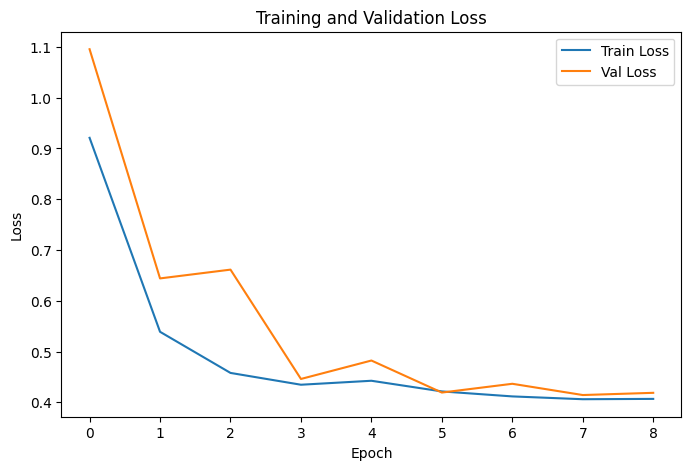

In [14]:
#loss
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

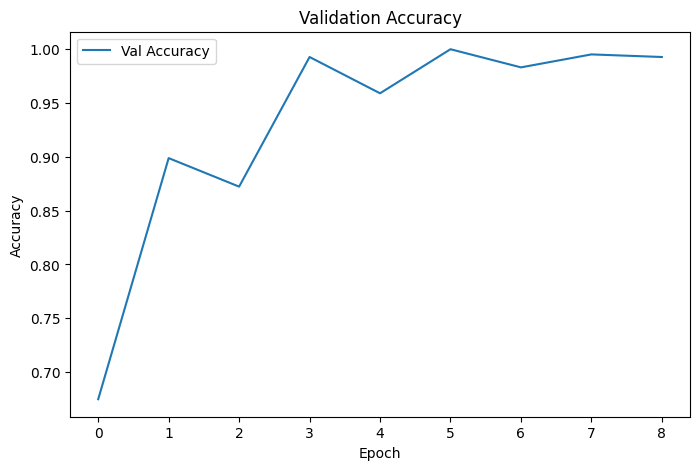

In [15]:
#acc
plt.figure(figsize=(8, 5))
plt.plot(val_accuracies, label="Val Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy")
plt.legend()
plt.show()

## Testing

### Load Best Model

In [16]:
# Use the best validation weights from this training run.
model.load_state_dict(best_model_wts)
model.eval()

print(
    f"Ready to test the best circuit model "
    f"(validation accuracy: {best_val_acc:.2%})."
)

Ready to test the best circuit model (validation accuracy: 100.00%).


### Test

Test accuracy: 100.00%

                  precision    recall  f1-score   support

band_pass_filter       1.00      1.00      1.00        84
 current_divider       1.00      1.00      1.00        84
high_pass_filter       1.00      1.00      1.00        83
 low_pass_filter       1.00      1.00      1.00        83
 voltage_divider       1.00      1.00      1.00        83

        accuracy                           1.00       417
       macro avg       1.00      1.00      1.00       417
    weighted avg       1.00      1.00      1.00       417



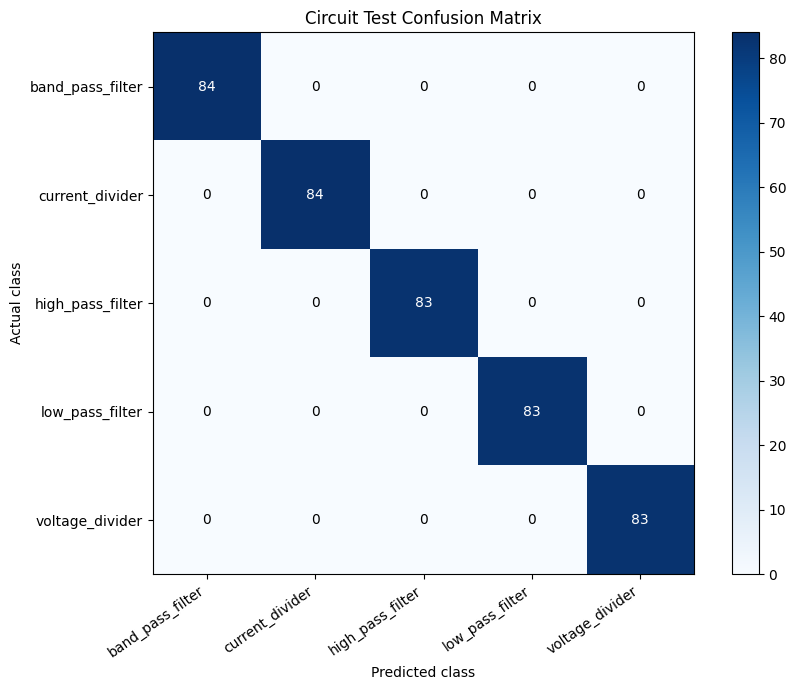

Results saved to: C:\Users\spiro\OneDrive\Documents\GitHub\intro_ai_project\circuit_resnet_results


In [17]:
model.eval()

test_preds = []
test_targets = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)

        outputs = model(images)
        preds = outputs.argmax(dim=1)

        test_preds.extend(preds.cpu().tolist())
        test_targets.extend(labels.tolist())

# Overall accuracy and results for each class.
label_ids = list(range(NUM_CLASSES))
test_acc = accuracy_score(test_targets, test_preds)

print(f"Test accuracy: {test_acc:.2%}\n")

print(
    classification_report(
        test_targets,
        test_preds,
        labels=label_ids,
        target_names=class_names,
        zero_division=0,
    )
)

# Confusion matrix: rows are actual classes, columns are predictions.
cm = confusion_matrix(
    test_targets,
    test_preds,
    labels=label_ids,
)

fig, ax = plt.subplots(figsize=(9, 7))
plot = ax.imshow(cm, interpolation="nearest", cmap="Blues")
fig.colorbar(plot, ax=ax)

ax.set(
    xticks=label_ids,
    yticks=label_ids,
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted class",
    ylabel="Actual class",
    title="Circuit Test Confusion Matrix",
)

plt.setp(ax.get_xticklabels(), rotation=35, ha="right")

for row in label_ids:
    for col in label_ids:
        ax.text(
            col,
            row,
            str(cm[row, col]),
            ha="center",
            va="center",
            color="white" if cm[row, col] > cm.max() / 2 else "black",
        )

fig.tight_layout()

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=150)
plt.show()

# Save each test image's actual and predicted class.
predictions = test_df[
    ["filename", "class", "template_id"]
].copy()

predictions["predicted_class"] = [
    idx_to_class[index] for index in test_preds
]

predictions.to_csv(
    RESULTS_DIR / "test_predictions.csv",
    index=False,
)

# Save numerical evaluation results.
report = classification_report(
    test_targets,
    test_preds,
    labels=label_ids,
    target_names=class_names,
    zero_division=0,
    output_dict=True,
)

(RESULTS_DIR / "test_metrics.json").write_text(
    json.dumps(
        {
            "test_accuracy": float(test_acc),
            "classification_report": report,
        },
        indent=2,
    ),
    encoding="utf-8",
)

print("Results saved to:", RESULTS_DIR.resolve())

### Test Any Image

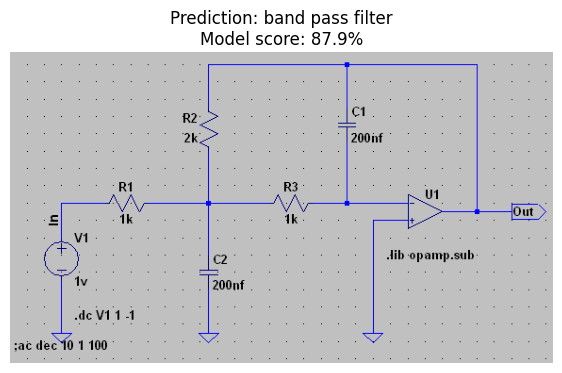

Scores for each class:
band pass filter    : 87.9%
current divider     : 9.8%
voltage divider     : 1.0%
low pass filter     : 0.9%
high pass filter    : 0.4%


In [28]:
IMAGE_PATH = Path("test_image_10.png")

if not IMAGE_PATH.is_file():
    raise FileNotFoundError(f"Image not found: {IMAGE_PATH.resolve()}")

# Open the picture and apply the same preprocessing used for testing.
with Image.open(IMAGE_PATH) as source:
    image = source.convert("RGB")

input_tensor = val_test_transform(image).unsqueeze(0).to(device)

# Predict without changing the model.
model.eval()

with torch.no_grad():
    outputs = model(input_tensor)
    probabilities = torch.softmax(outputs, dim=1)[0].cpu()

predicted_index = probabilities.argmax().item()
predicted_class = idx_to_class[predicted_index]
score = probabilities[predicted_index].item()

# Show the uploaded image and prediction.
plt.figure(figsize=(7, 7))
plt.imshow(image)
plt.axis("off")
plt.title(
    f"Prediction: {predicted_class.replace('_', ' ')}\n"
    f"Model score: {score:.1%}"
)
plt.show()

# Show the scores for all five classes.
print("Scores for each class:")

for index in probabilities.argsort(descending=True).tolist():
    name = idx_to_class[index].replace("_", " ")
    print(f"{name:20s}: {probabilities[index].item():.1%}")